# 09 — Resultados y recomendaciones para el fondo

## Objetivo

Traducir los resultados en las dos decisiones del interlocutor:

1. **¿Qué propiedades visitar u ofertar?** Ranking de subvaluación.
2. **¿Conviene comprar y refaccionar una unidad puntual?** Modelo de flipping.

Con los supuestos de costo con fuente (notebook 07), el flipping no resulta
rentable en general (H3, notebook 08). Por eso, la recomendación principal es el
ranking de subvaluación confirmado por dos métodos y revisado a mano, y el
flipping se usa como herramienta de oferta (precio máximo), no como lista de
compras.

Fuentes: `remax_deptos_features.csv` (notebook 03),
`oportunidades_benchmark_ajustado.csv` (notebook 11) y
`flipping_ranking_priorizado.csv` (notebook 07).

In [1]:
# Entorno: ubicar la raíz del repositorio (la carpeta que contiene src/)
import os
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / "src").is_dir() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import (BASE_FEATURES, PROCESSED_DIR, DATA_DIR, DESCUENTO_NEGOCIABLE_PCT,
                        MARGEN_MINIMO_PCT, UMBRAL_GAP)
from src import revision_avisos as rv

sns.set_theme(style="whitegrid")
feat = pd.read_csv(BASE_FEATURES)
ajust = pd.read_csv(PROCESSED_DIR / "oportunidades_benchmark_ajustado.csv")
flip = pd.read_csv(PROCESSED_DIR / "flipping_ranking_priorizado.csv")
print("Avisos:", len(feat), "| con benchmark ajustado:", len(ajust), "| evaluados para flipping:", len(flip))

Avisos: 9499 | con benchmark ajustado: 9194 | evaluados para flipping: 428


## 1. Decisión 1 — Qué propiedades visitar

Se consideran **candidatas de mayor confianza** las propiedades que cumplen las
dos condiciones siguientes:

- son baratas según el benchmark jerárquico (gap ≥ 25 % y cuartil inferior del
  estrato) **y** según el benchmark ajustado por antigüedad y características
  (notebook 11);
- no tienen indicadores de posible error de carga (categoría `Barata`, no
  `Barata_requiere_verificacion`).

In [2]:
cols_feat = ["ID", "Clasificacion_Oportunidad", "Estado_Publicacion", "Precio_Valor",
             "Superficie_Homogeneizada_m2", "Ambientes", "Comuna", "Precio_Esperado",
             "N_Comparables", "Nivel_Benchmark", "Link", "Titulo", "Descripcion",
             "Barrio", "Direccion", "Latitud", "Longitud"]
op = ajust.merge(feat[cols_feat], on="ID", how="left")

resumen = pd.crosstab(op["Categoria_Doble"], op["Clasificacion_Oportunidad"], margins=True)
display(resumen)

alta = op[op["Categoria_Doble"].eq("Confirmada_por_ambos") & op["Clasificacion_Oportunidad"].eq("Barata")].copy()
print("Candidatas automáticas (antes de la revisión de la sección 1.1):", len(alta))

Clasificacion_Oportunidad,Barata,Barata_requiere_verificacion,Precio_de_mercado,All
Categoria_Doble,,,,
Confirmada_por_ambos,249,76,0,325
No_barata,0,0,7704,7704
Solo_benchmark,443,33,0,476
Solo_hedonico,0,0,272,272
All,692,109,7976,8777


Candidatas automáticas (antes de la revisión de la sección 1.1): 249


**Evidencia de que la señal es real.** Si las baratas fueran solo errores o
avisos mal cargados, no deberían atraer más demanda que el resto. Se compara la
proporción de avisos reservados o en negociación. Con una única captura esto
muestra demanda, no velocidad de venta.

In [3]:
op["Con_operacion"] = op["Estado_Publicacion"].isin(["reserved", "negotiation"])
op["Grupo"] = np.select(
    [op.index.isin(alta.index), op["Categoria_Doble"].ne("No_barata")],
    ["Confirmada por ambos (sin error)", "Barata por un solo método"], "No barata")
liq = (op.groupby("Grupo")["Con_operacion"].agg(["mean", "size"])
       .rename(columns={"mean": "% reservado o en negociación", "size": "Avisos"}))
liq["% reservado o en negociación"] = (liq["% reservado o en negociación"] * 100).round(1)
display(liq)

from scipy import stats
tabla = pd.crosstab(op["Grupo"].eq("Confirmada por ambos (sin error)"), op["Con_operacion"])
chi2, p, *_ = stats.chi2_contingency(tabla)
print(f"Chi-cuadrado confirmadas vs. resto: chi2 = {chi2:.1f}, p = {p:.1e}")

,% reservado o en negociación,Avisos
Grupo,,
Barata por un solo método,32.5,1241
Confirmada por ambos (sin error),40.6,249
No barata,23.0,7704


Chi-cuadrado confirmadas vs. resto: chi2 = 33.4, p = 7.5e-09


,Candidatas,Gap_mediano_pct,Precio_mediano_USD,% de la oferta del barrio
Barrio_Oficial,,,,
Palermo,20,29.3,129900.0,1.8
Recoleta,18,32.4,98000.0,2.9
Balvanera,17,30.8,90000.0,2.9
Caballito,17,31.4,106000.0,2.1
San Nicolas,15,32.6,79999.0,5.5
Almagro,13,27.9,79000.0,2.4
Flores,13,37.9,59000.0,3.1
Retiro,11,34.1,75000.0,5.2
Belgrano,10,32.0,190000.0,2.0


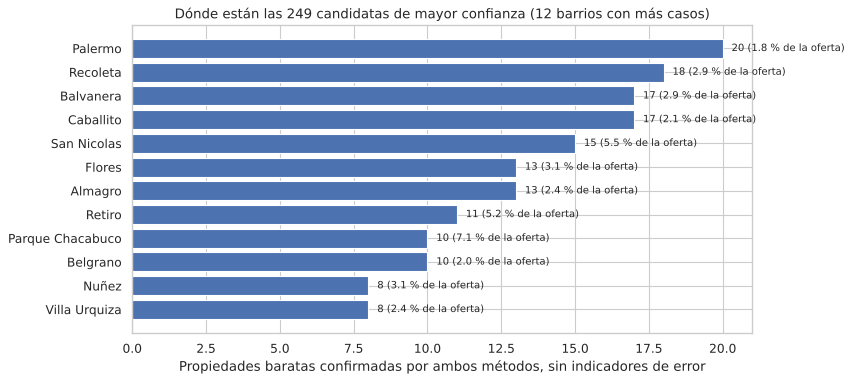

In [4]:
por_barrio = (alta.groupby("Barrio_Oficial")
              .agg(Candidatas=("ID", "size"), Gap_mediano_pct=("Gap_Hedonico_pct", "median"),
                   Precio_mediano_USD=("Precio_Valor", "median"))
              .sort_values("Candidatas", ascending=False))
total_barrio = op.groupby("Barrio_Oficial").size()
por_barrio["% de la oferta del barrio"] = (por_barrio["Candidatas"] / total_barrio.reindex(por_barrio.index) * 100).round(1)
display(por_barrio.head(12).round(1))

fig, ax = plt.subplots(figsize=(10, 5))
top = por_barrio.head(12).sort_values("Candidatas")
ax.barh(top.index, top["Candidatas"], color="#4C72B0")
for y, (n, pct) in enumerate(zip(top["Candidatas"], top["% de la oferta del barrio"])):
    ax.text(n + 0.3, y, f"{n} ({pct:.1f} % de la oferta)", va="center", fontsize=9)
ax.set(title=f"Dónde están las {len(alta)} candidatas de mayor confianza (12 barrios con más casos)",
       xlabel="Propiedades baratas confirmadas por ambos métodos, sin indicadores de error", ylabel="")
plt.show()

### Ranking de visitas (antes de la revisión)

Se ordena por el gap del benchmark ajustado, que es el método con menor error
fuera de muestra (MAPE de 15,3 % contra 19,6 %, notebook 11). Para que el
ranking no dependa de un único método, se informa también el gap del benchmark
jerárquico.

**Sensibilidad del ranking.** Se compara el top 50 con el ordenamiento por el
otro gap y con un promedio de ambos.

In [5]:
alta = alta.sort_values("Gap_Hedonico_pct", ascending=False).reset_index(drop=True)
alta["Ranking_Original"] = np.arange(1, len(alta) + 1)
cols = ["ID", "Barrio_Oficial", "Ambientes", "Precio_Valor", "Precio_Esperado",
        "Gap_Hedonico_pct", "Gap_Benchmark_pct", "N_Comparables", "Estado_Publicacion"]
display(alta[["Ranking_Original"] + cols].head(15).round(1))

top_h = set(alta.nlargest(50, "Gap_Hedonico_pct")["ID"])
top_b = set(alta.nlargest(50, "Gap_Benchmark_pct")["ID"])
top_m = set(alta.assign(m=(alta["Gap_Hedonico_pct"] + alta["Gap_Benchmark_pct"]) / 2).nlargest(50, "m")["ID"])
print(f"Top 50: coincidencia con el orden por gap jerárquico {len(top_h & top_b)}/50; "
      f"con el promedio de ambos gaps {len(top_h & top_m)}/50")
print("Spearman entre ambos gaps (candidatas):",
      round(stats.spearmanr(alta["Gap_Hedonico_pct"], alta["Gap_Benchmark_pct"])[0], 2))


,Ranking_Original,ID,Barrio_Oficial,Ambientes,Precio_Valor,Precio_Esperado,Gap_Hedonico_pct,Gap_Benchmark_pct,N_Comparables,Estado_Publicacion
0,1,657232,Chacarita,3,78900.0,187956.4,61.1,58.0,12.0,active
1,2,625637,Flores,4,59000.0,111691.7,60.0,47.2,29.0,active
2,3,631831,Barracas,3,55000.0,97509.0,59.6,43.6,10.0,active
3,4,566604,Villa Crespo,1,40000.0,96811.8,54.2,58.7,27.0,reserved
4,5,600590,Recoleta,1,100000.0,145149.1,53.9,31.1,26.0,negotiation
5,6,530138,Flores,3,55000.0,135104.9,53.5,59.3,12.0,active
6,7,656715,Villa Urquiza,5,180000.0,372937.5,52.5,51.7,13.0,active
7,8,654884,Nuñez,1,59000.0,106231.9,51.8,44.5,16.0,active
8,9,601236,Parque Chacabuco,3,80000.0,137772.4,50.5,41.9,16.0,active
9,10,13931,San Nicolas,4,150000.0,352000.0,50.5,57.4,49.0,active


Top 50: coincidencia con el orden por gap jerárquico 20/50; con el promedio de ambos gaps 32/50
Spearman entre ambos gaps (candidatas): 0.46


### 1.1. Revisión de la lista antes de presentarla

Un aviso muy por debajo de sus comparables puede no ser una oportunidad sino un
producto distinto: un precio que es solo un anticipo, la venta de una nuda
propiedad, una unidad escriturada como cochera, una oficina o un aviso con las
coordenadas en otro barrio (y, por lo tanto, comparado con el barrio
equivocado). Por eso, antes de presentar la lista se hacen dos controles:

1. **Automático, sobre las candidatas** (`src/revision_avisos.py`). Se buscan en
   el título y la descripción señales de precio parcial, derechos parciales y
   destino distinto por escritura (→ *Excluir*) y de uso no residencial, PH,
   inquilino, sucesión o posible duplicado (→ *Verificar*). La ubicación se
   controla comparando el barrio que declara el aviso con el barrio oficial
   asignado por coordenadas: si difieren y el punto está a más de 3 km del
   centro del barrio declarado, no es un caso de límite entre barrios vecinos
   sino un error de coordenadas (→ *Excluir*).
2. **Manual, sobre los primeros puestos.** Se leyeron título y descripción de
   los primeros 42 puestos y se verificó la ubicación
   (`data/validation/revision_lista_visitas.csv`, con el motivo de cada
   decisión). La decisión manual prevalece sobre la automática.


In [6]:
rev = rv.revisar(alta, df_mercado=feat)
manual = pd.read_csv(DATA_DIR / "validation" / "revision_lista_visitas.csv")
rev = rev.merge(manual[["ID", "Decision_Manual", "Motivo_Manual"]], on="ID", how="left")
rev["Revision"] = rev["Decision_Manual"].fillna(rev["Revision_Auto"].replace("Sin observaciones", "Mantener"))
rev["Motivo_Revision"] = rev["Motivo_Manual"].fillna(rev["Motivo_Auto"])

print("Señales automáticas en las candidatas:")
display(rev.filter(like="Senal_").sum().to_frame("Avisos"))
display(pd.crosstab(rev["Revision_Auto"], rev["Decision_Manual"].fillna("(sin lectura manual)"), margins=True))
excluidas = rev[rev["Revision"].eq("Excluir")]
display(excluidas[["Ranking_Original", "ID", "Barrio_Oficial", "Barrio", "Precio_Valor",
                   "Gap_Hedonico_pct", "Motivo_Revision"]].round(1))
print("Avisos con ubicación inconsistente en toda la base:",
      int(rv.ubicacion_inconsistente(feat)[0].sum()), "de", len(feat))


Señales automáticas en las candidatas:


,Avisos
Senal_Precio_Parcial,2
Senal_Derechos_Parciales,2
Senal_Escritura_Otro_Uso,1
Senal_Ubicacion_Inconsistente,3
Senal_Uso_No_Residencial,7
Senal_Tipologia_PH,4
Senal_Con_Inquilino,13
Senal_Sucesion,3
Senal_Posible_Duplicado,6


Decision_Manual,(sin lectura manual),Excluir,Mantener,Verificar,All
Revision_Auto,,,,,
Excluir,2,6,0,0,8
Sin observaciones,184,1,24,1,210
Verificar,21,3,0,7,31
All,207,10,24,8,249


,Ranking_Original,ID,Barrio_Oficial,Barrio,Precio_Valor,Gap_Hedonico_pct,Motivo_Revision
3,4,566604,Villa Crespo,San Telmo,40000.0,54.2,"Ubicación inconsistente: el título dice Barracas, el aviso San Telmo (Perú 1600) y las coordenadas caen en Villa Crespo. El benchmark se calculó contra otro barrio."
6,7,656715,Villa Urquiza,Villa Urquiza,180000.0,52.5,Se publica como 'loft oficina' multipropósito: no es un departamento de vivienda comparable.
7,8,654884,Nuñez,Nuñez,59000.0,51.8,El precio publicado es un anticipo del 50 % (contado USD 127.000).
12,13,353262,Nuñez,Balvanera,125000.0,48.9,Ubicación inconsistente: título y descripción dicen Balvanera (Azcuénaga 200) y las coordenadas caen en Núñez. Con comparables de Balvanera la señal casi desaparece.
14,15,568677,Recoleta,Barrio Norte,40000.0,47.4,Venta de nuda propiedad: el precio no corresponde al dominio pleno.
17,18,582968,Villa Luro,Villa Luro,36000.0,46.0,"Por escritura, la unidad funcional consta como cochera."
23,24,617891,Villa Crespo,San Nicolás,97000.0,43.2,Ubicación inconsistente: el aviso dice San Nicolás (Maipú 300) y las coordenadas caen en Villa Crespo.
34,35,620010,San Nicolas,San Nicolás,122900.0,40.2,"Oficina corporativa (despachos y sala de reuniones), no vivienda."
40,41,628483,Villa Urquiza,Villa Urquiza,120000.0,39.5,La descripción aclara que es un PH en tres plantas: tipología fuera del alcance.
41,42,620009,San Nicolas,San Nicolás,104900.0,39.3,"Oficina comercial (despachos y área operativa), no vivienda."


Avisos con ubicación inconsistente en toda la base: 11 de 9499


**Lectura.** Entre los primeros puestos aparecen justamente los casos que
inflan la brecha sin ser oportunidades: el puesto 8 publica como precio un
anticipo del 50 %, el 15 vende una nuda propiedad, el 18 está escriturado como
cochera, el 13 tiene las coordenadas en Núñez aunque el aviso es de Balvanera, y
hay oficinas y un PH que no son departamentos de vivienda. El control automático
solo detecta parte de esto (las oficinas y el PH los marca para verificar, no
para excluir); la lectura manual de los primeros puestos sigue siendo necesaria.
Los once avisos de toda la base con ubicación inconsistente también participan
como comparables de otros barrios: es una limitación del benchmark que conviene
corregir en la limpieza.


In [7]:
visitas = rev[rev["Revision"].ne("Excluir")].reset_index(drop=True)
visitas.insert(0, "Ranking_Visita", np.arange(1, len(visitas) + 1))
print("Candidatas de mayor confianza después de la revisión:", len(visitas),
      f"(se excluyeron {len(rev) - len(visitas)})")
display(visitas["Revision"].value_counts().to_frame("Avisos"))
display(visitas[["Ranking_Visita", "Ranking_Original"] + cols + ["Revision", "Motivo_Revision"]].head(20).round(1))

ruta = PROCESSED_DIR / "ranking_visitas.csv"
visitas[["Ranking_Visita", "Ranking_Original"] + cols
        + ["Revision", "Motivo_Revision", "Superficie_Homogeneizada_m2", "Comuna", "Link", "Titulo"]
        ].to_csv(ruta, index=False, encoding="utf-8-sig")
print("Exportado:", ruta.name, len(visitas), "filas")


Candidatas de mayor confianza después de la revisión: 237 (se excluyeron 12)


,Avisos
Revision,
Mantener,208
Verificar,29


,Ranking_Visita,Ranking_Original,ID,Barrio_Oficial,Ambientes,Precio_Valor,Precio_Esperado,Gap_Hedonico_pct,Gap_Benchmark_pct,N_Comparables,Estado_Publicacion,Revision,Motivo_Revision
0,1,1,657232,Chacarita,3,78900.0,187956.4,61.1,58.0,12.0,active,Mantener,Dúplex 3 ambientes con balcón; barrio y dirección coinciden (Chacarita).
1,2,2,625637,Flores,4,59000.0,111691.7,60.0,47.2,29.0,active,Mantener,"4 ambientes en torre, piso 12; sin observaciones en el texto."
2,3,3,631831,Barracas,3,55000.0,97509.0,59.6,43.6,10.0,active,Mantener,"3 ambientes, 66 m²; sin observaciones en el texto."
3,4,5,600590,Recoleta,1,100000.0,145149.1,53.9,31.1,26.0,negotiation,Verificar,Loft que se ofrece como consultorio u oficina y 'a estrenar'; confirmar que es vivienda usada.
4,5,6,530138,Flores,3,55000.0,135104.9,53.5,59.3,12.0,active,Mantener,3 ambientes con balcón en Av. Lafuente; sin observaciones.
5,6,9,601236,Parque Chacabuco,3,80000.0,137772.4,50.5,41.9,16.0,active,Mantener,3 ambientes en torre; sin observaciones.
6,7,10,13931,San Nicolas,4,150000.0,352000.0,50.5,57.4,49.0,active,Verificar,Se vende con contrato de alquiler vigente hasta mayo de 2027; el inquilino explica parte del descuento.
7,8,11,581149,Recoleta,5,180000.0,362707.8,50.0,50.4,13.0,active,Verificar,Planta baja que funcionó como clínica odontológica; confirmar destino y estado.
8,9,12,357762,Saavedra,5,135000.0,261775.3,49.8,48.4,13.0,reserved,Verificar,"El texto invita a 'proyectar reformas': puede necesitar obra, lo que explicaría el precio."
9,10,14,611544,Flores,2,39000.0,69535.4,47.8,43.9,12.0,reserved,Mantener,2 ambientes con balcón; sin observaciones.


Exportado: ranking_visitas.csv 237 filas


## 2. Decisión 2 — Flipping: hasta cuánto ofertar

Con los supuestos con fuente, comprar al precio publicado y refaccionar no
resulta rentable en general (notebook 07). La herramienta útil para el fondo es
el **precio máximo de oferta** de cada unidad: el mayor precio al que se
cumplen a la vez el margen mínimo en el escenario base, un ROI no negativo en el
conservador y la brecha mínima, una vez descontados obra, tenencia, transacción
y costo de oportunidad.

,Unidades
Decision,
Descartar,428


,Unidades
Robustez_Economica,
No rentable,366
Rentable solo en optimista,60
Rentable en base y optimista,2


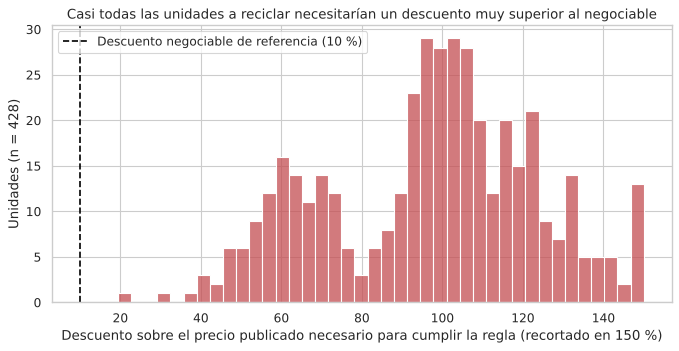

Unidades que cumplirían la regla con un descuento ≤ 30 % (lista de seguimiento): 1


,Ranking_Priorizado,ID,Barrio_Oficial,Precio_Valor,Precio_Max_Oferta_USD,Descuento_Requerido_pct,Restriccion_Activa,Nivel_Obra,ROI_Optimista_pct,Cantidad_Alertas,Decision
0,1,550445,Palermo,99900.0,80542.2,19.4,ROI conservador ≥ 0,Media,47.2,1,Descartar


In [8]:
display(flip["Decision"].value_counts().to_frame("Unidades"))
display(flip["Robustez_Economica"].value_counts().to_frame("Unidades"))

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.histplot(flip["Descuento_Requerido_pct"].clip(upper=150), bins=40, ax=ax, color="#C44E52")
ax.axvline(DESCUENTO_NEGOCIABLE_PCT, color="black", ls="--",
           label=f"Descuento negociable de referencia ({DESCUENTO_NEGOCIABLE_PCT} %)")
ax.set(title="Casi todas las unidades a reciclar necesitarían un descuento muy superior al negociable",
       xlabel="Descuento sobre el precio publicado necesario para cumplir la regla (recortado en 150 %)",
       ylabel=f"Unidades (n = {len(flip)})")
ax.legend()
plt.show()

seg = flip[flip["Descuento_Requerido_pct"] <= 30]
print("Unidades que cumplirían la regla con un descuento ≤ 30 % (lista de seguimiento):", len(seg))
display(seg[["Ranking_Priorizado", "ID", "Barrio_Oficial", "Precio_Valor", "Precio_Max_Oferta_USD",
             "Descuento_Requerido_pct", "Restriccion_Activa", "Nivel_Obra", "ROI_Optimista_pct", "Cantidad_Alertas",
             "Decision"]].round(1))

## 3. Recomendaciones

**Para la decisión 1 (qué visitar).**

1. Priorizar las 237 candidatas de mayor confianza del ranking de visitas
   (`data/processed/ranking_visitas.csv`): son baratas según los dos benchmarks,
   no tienen indicadores de error de carga y pasaron la revisión de la sección
   1.1. Los dos benchmarks usan los mismos avisos, así que su coincidencia es
   consistencia interna, no una confirmación independiente. El orden exacto es
   sensible al método (solo 20 del top 50 coinciden con el orden por el otro
   gap), así que conviene usarlo por tramos (por ejemplo, los primeros 50) y no
   por puesto.
2. Las 29 marcadas como *Verificar* tienen una razón identificable para el
   descuento (inquilino, uso profesional, sucesión, posible duplicado): el
   descuento puede ser justo y no una oportunidad. Confirmarlo antes de visitar.
3. Contactar pronto a las candidatas: el 41 % ya está reservado o en
   negociación, contra el 23 % de las no baratas. Atraen más demanda, lo que
   sugiere que la señal no es solo error de carga. Con una sola captura no se
   puede medir la velocidad con que salen del mercado.
4. Antes de ofertar, verificar el aviso: superficie, estado, piso y situación
   legal. Los modelos no observan esas variables, y su error mediano ronda el 12 %.

**Para la decisión 2 (flipping).**

5. No adoptar el flipping de unidades a reciclar como estrategia general a
   precio publicado: con los costos con fuente, el descuento de entrada no paga
   la obra.
6. Usar el **precio máximo de oferta** como techo de negociación: ofertar ese
   valor y comprar solo si se acepta. Al exigir también un ROI no negativo en el
   escenario conservador, el descuento necesario es mayor: ninguna unidad cumple
   la regla con un descuento de hasta 10 % y solo una con hasta 30 %.
7. Antes de cualquier oferta, obtener una cotización de obra propia y una visita
   técnica: el alcance real de la obra es el supuesto que más mueve el resultado.


## 4. Por qué casi nada cierra: la elección de RE/MAX como fuente

La premisa del proyecto es encontrar propiedades **publicadas por debajo de su
valor**, es decir, errores de precio. Esa premisa depende de quién fija el
precio. En RE/MAX, cada aviso lo publica un agente que, antes de publicar, hace
una tasación por comparables, y cuya comisión depende de vender: tiene
incentivos y herramientas para no publicar muy por debajo del mercado. Por eso,
en esta fuente es poco probable encontrar errores de valuación groseros. Los
propios resultados son coherentes con esa lectura:

- **Lo que aparece "muy barato" suele ser otro producto.** Entre los primeros
  puestos del ranking hay anticipos, una nuda propiedad, una cochera, oficinas,
  un PH y coordenadas en otro barrio (sección 1.1). La cola de la distribución
  de la brecha está poblada por diferencias de producto o de carga, no por
  tasaciones equivocadas.
- **El mercado ya descuenta el estado, pero no la obra.** Las unidades a
  reciclar se publican unos 17 puntos por debajo de sus comparables (H1), lo que
  cubre la transacción y la tenencia pero no una obra media o integral
  (notebook 07). Los descuentos de 40 % a 100 % que haría falta negociar para
  que el flipping cierre no son un objetivo de negociación realista frente a un
  precio que ya fijó un tasador.
- **Lo que queda es dispersión que los modelos no explican.** Después de
  controlar ubicación, tamaño, antigüedad y características, la brecha restante
  mezcla atributos no observados (piso, luz, terminaciones, estado del edificio)
  con descuentos reales. Con estos datos no se pueden separar.

**Qué cambia en la lectura del resultado.** Que casi nada cierre no es una falla
del método, sino información sobre la fuente: en avisos tasados por un agente,
"buscar precios mal puestos" rinde poco y la oportunidad está en descuentos con
una causa que el fondo puede aceptar o resolver (inquilino, sucesión, obra
liviana). La premisa original es más plausible en portales donde publican
particulares sin tasación previa (por ejemplo, los avisos de dueño directo en
Zonaprop o MercadoLibre). El siguiente paso natural es correr el mismo pipeline
sobre avisos de particulares y comparar la proporción de baratas y la
distribución de la brecha: si la premisa es correcta, debería haber más baratas
y menos explicadas por diferencias de producto.


## 5. Limitaciones

- Precios de publicación, no de cierre, en una sola fuente (RE/MAX) y una sola
  captura.
- El estado de la propiedad se infiere del texto (validado manualmente sobre
  muestras, notebook 06).
- Los costos de obra son supuestos con fuente secundaria, no cotizaciones
  propias.
- Las recomendaciones priorizan qué investigar; no son una tasación individual.

## 6. Próximos pasos

- Replicar el pipeline sobre avisos de particulares (sección 4).
- Corregir en la limpieza las coordenadas de los 11 avisos con ubicación
  inconsistente y recalcular los benchmarks.
- Capturas sucesivas para medir el tiempo de venta y validar que las baratas se
  venden antes.
- Cotizaciones reales por nivel de obra para recalibrar el modelo de flipping.
- Incorporar las fuentes externas complementarias (subte, espacios verdes) al
  benchmark ajustado.